# Cleaning Messy Data: A Student Survey Walkthrough

In this notebook we start with a survey of 106 students. The file is messy, the way real data usually is. We will find the problems, fix them, and check our work.

A note before we get started: there is a lot of computer code in this notebook.  If you have not coded before, don't worry!  The focus of this exercise is to illustrate how data actually looks like in the wild.  Code is simply a tool we use to interact with data.  We will primarily be using code to load data, examine it, and fix it.

**What you'll practice**
1. Looking at a dataset before you touch it
2. Finding missing values, including codes like `-` that pandas does not recognize on its own
3. Removing duplicate rows
4. Standardizing text categories
5. Converting text into numbers and dates
6. Handling impossible values and placeholder codes like `999`
7. Checking the result and saving a clean copy

Run each cell in order with **Shift + Enter**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/jer395/IEEE-NJ-Coast-YP/refs/heads/main/data/survey_responses_messy.csv"

df = pd.read_csv(DATA_URL)
df_raw = df.copy()  # keep an untouched copy so we can compare before and after

df.head(10)

## Step 1: First look

Before cleaning anything, we want to know the size of the data, the column types, and what the values look like.

In [ ]:
print("Rows and columns:", df.shape, "\n")

print("Column names:", df.columns.tolist(), "\n")
print("Column data types:")
print("—"*31)
print(df.dtypes.to_string())

There is a lot of information here, but don't get overwhelmed!  This is "metadata," which is just extra information about the type of data we're dealing with.  From the first line, we can see that there are 106 rows and 9 columns.  For today, we are more concerned with the table that is shown.

Two things to notice here. The `gpa` and `study_hours_per_week` cokumns from our dataset have the data type "`object`".  That means that the values/rows within those columns are treated as *words* rather than numbers (which are called *floats* in computer programming), even though they should be numbers. So, something in those columns is not a regular number. This could be a problem because we cannot do basic math on words (for example, we cannot add words together).  Let's look at the entries that cannot be read as numbers.

In [ ]:
gpa_as_number = pd.to_numeric(df["gpa"], errors="coerce")
df.loc[gpa_as_number.isna() & df["gpa"].notna(), "gpa"]

Don't worry too much about the code.  Just know that the table which is shown includes GPAs that, for some reason, are not saved as numbers in our file.

Some GPAs use a comma instead of a decimal point, like `3,45`. Python reads that as text, not as a number. Keep this in mind for later.

## Step 2: Missing values

Pandas (which is a collection of predefined code that helps us work with data) already treats certain special values as "missing," such as blank cells and `N/A`. Let's count how many values are missing in each column.

In [ ]:
df.isna().sum()

Now look at the `study_hours_per_week` column. It is not showing any missing values, but we know some answers are `-`. Pandas does not treat `-` as missing by default, so, we have to tell it.

In [ ]:
df = pd.read_csv(DATA_URL, na_values=["-"])

print("Extra missing values found after telling pandas about '-':")
print(df.isna().sum() - df_raw.isna().sum())

## Step 3: Duplicate rows

Sometimes, datasets may contain the exact same row multiple times.  For some datasets, that is fine.  However, for many datasets, each row should correspond to a single unique record of something in the real world.

In our dataset, each row represents a survey entry.  Additionally, in our dataset, each row has a unique number &mdash; or an "ID" &mdash; and is given by the value in the row's `response_id` column.  We can use the row's ID to identify a unique survey submission.  That means that if we see the same survey response ID multiple times, our dataset contains duplicate copies of the same survey response.

Let's check whether any rows are exact copies, and whether any response ID appears more than once.  If there are any duplicates, we only want to maintain a single copy and delete the rest.

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

# Look at the duplicates side by side with their originals
df[df.duplicated(keep=False)].sort_values("response_id").head(6)

In [ ]:
df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))
print("Duplicate response IDs left:", df["response_id"].duplicated().sum())

Now we are left with only 100 rows even though we started with 106.  That means that 6 rows were duplicates and we successfully removed them from our dataset.

## Step 4: Standardize text categories

A separate common issue is when the same value in a dataset is represent in many different ways.

A computer treats `"Biology"`, `"biology"`, and `"BIOLOGY "` as three different answers. Let's see how many versions of each major we have.

In [ ]:
df["major"].value_counts(dropna=False)

In our dataset, we have seventeen different spellings which really corresponds to just six unique majors.  We also have blank cells. We will map every version to one standard name. Notice that we first make everything lowercase and remove extra spaces, so we only have to write each variant once.

In [ ]:
major_map = {
    "computer science": "Computer Science", "cs": "Computer Science", "comp sci": "Computer Science",
    "biology": "Biology", "bio": "Biology",
    "psychology": "Psychology", "psych": "Psychology",
    "business": "Business", "bus.": "Business",
    "engineering": "Engineering", "engr": "Engineering",
    "undeclared": "Undeclared", "undecided": "Undeclared",
}

normalized = df["major"].str.strip().str.lower()

# A blank major counts as "Undeclared", but this is a judgment call.
df["major"] = normalized.map(major_map).fillna("Undeclared")

df["major"].value_counts()

In [ ]:
# Do something similar for the "home_state" column, which has non-standard categories.
state_map = {
    "nj": "NJ", "new jersey": "NJ",
    "ny": "NY", "new york": "NY",
    "pa": "PA", "pennsylvania": "PA",
    "ct": "CT", "conn.": "CT",
}

normalized_state = df["home_state"].str.strip().str.lower()

df["home_state"] = normalized_state.map(state_map)
df["home_state"].value_counts()

## Step 5: Turn text into numbers

Now we fix the GPA column. We replace commas with decimal points and convert the text into numbers (so, `"3,45"` becomes `3.45`). Anything that still cannot be converted becomes missing (`NaN`).

In [ ]:
gpa_text = df["gpa"].astype(str).str.replace(",", ".", regex=False)
df["gpa"] = pd.to_numeric(gpa_text, errors="coerce")

# GPA should be between 0 and 4. Let's see what is out of range.
print("GPA values outside 0 to 4:", df.loc[(~df["gpa"].between(0, 4)) & df["gpa"].notna(), "gpa"].tolist())

# Turn impossible values into missing. We do not guess what 40 was supposed to be.
df.loc[~df["gpa"].between(0, 4), "gpa"] = np.nan

df["gpa"].describe()

Now, let's fix the `study_hours_per_week` column.  Initially, we saw that it included non-number values.

In [ ]:
df[pd.to_numeric(df["study_hours_per_week"], errors="coerce").isna()]["study_hours_per_week"]

It seems that there are some values which are not numbers.  Also, some people wrote that they studied for more than 10 hours a week as "10+" hours.  This is a logical thing to do as a user filling out a survey, but we need an actual number.

For now, we can ignore the missing values and remove the "+" sign from `"10+"` to become just `10` which is a reasonable guess.  That should fix everything, right?

In [ ]:
hours_text = df["study_hours_per_week"].astype(str).str.replace("+", "", regex=False)
df["study_hours_per_week"] = pd.to_numeric(hours_text, errors="coerce")

df.loc[~df["study_hours_per_week"].between(0, 100), "study_hours_per_week"]

Well, not quite.  As it turns out, even if you have all numeric values (ignoring the missing values), the data itself might not be valid.  Here, we see several people have indicated that they studied for -5 hours.  This is an actual number but is not actually possible!  We can treat those as missing values instead of guessing what it should be.  After addressing that, we can ignore the missing values and calculate basic statistics.

In [ ]:
df.loc[~df["study_hours_per_week"].between(0, 100), "study_hours_per_week"] = np.nan
df["study_hours_per_week"].describe()

## Step 6: Placeholder codes and impossible values

Some people type codes instead of leaving a blank. In this survey, `999` was used to mean "I don't know." If we keep it, the average commute time will be wrong. Let's look at the largest values first.

In [ ]:
print("Largest commute before cleaning:", df["commute_minutes"].max())
df["commute_minutes"] = df["commute_minutes"].replace(999, np.nan)     # substitute the "idk" placeholder with a missing value
print("Largest commute after cleaning:", df["commute_minutes"].max())

In [ ]:
print("Largest 3 age values before cleaning:", sorted(df["age"].dropna().unique().tolist())[-3:])

It's not immediately clear what 214 should represent: 21? 14? 24? Something else?  Instead of guessing, we can overwrite this as a missing value and assume that only valid ages would be between 16 and 30 years of age.

In [ ]:
# Ages should be between 16 and 30 for this survey
df.loc[~df["age"].between(16, 30), "age"] = np.nan
df["age"].describe()

## Step 7: Yes/No answers and dates

The campus question was answered as `"Yes"`, `"yes"`, `"Y"`, `"No"`, `"no"`, and `"N"` (which are *words*). We will convert these to `True` and `False` (which are standard data types).

The submission dates are also in more than one format. Some are `2026-09-07`, some are `09/25/2026`, and some are `Sep 14 2026`. We will let pandas figure out each format.

In [ ]:
df["lives_on_campus"].head(5)

In [ ]:
df["submitted_on"].head(5)

In [ ]:
campus_map = {"yes": True, "y": True, "no": False, "n": False}
df["lives_on_campus"] = (
    df["lives_on_campus"].str.strip().str.lower().map(campus_map).astype("boolean")
)

df["submitted_on"] = pd.to_datetime(df["submitted_on"], format="mixed")

df[["submitted_on", "lives_on_campus"]].head()

## Step 8: Check our work

Let's compare the dataset before and after. We want to see how many rows we kept, and how many missing values we have now.

In [ ]:
print(f"Rows: {len(df_raw)} before cleaning -> {len(df)} after cleaning")
print()
df.info()
print()
df.isna().sum()

## Step 9: Look at the cleaned data

Clean data is easier to understand. Let's make two quick charts.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["major"].value_counts().plot(kind="barh", ax=axes[0], title="Students by major")
df["gpa"].plot(kind="hist", bins=12, ax=axes[1], title="GPA distribution")

plt.tight_layout()
plt.show()

## Step 10: Save a clean copy

We'll save the cleaned data so you can use it in future work.

In [ ]:
df.to_csv("sample_data/survey_clean.csv", index=False)

try:
    from google.colab import files
    files.download("survey_clean.csv")
except ImportError:
    print("Not running in Colab. The file was saved as survey_clean.csv in the current folder.")

## Reflection questions

1. Which problem was the hardest to spot? Why?
2. We turned a blank major into "Undeclared" and turned `40` GPA into missing. What would you do differently, and what could go wrong with each choice?
3. Before cleaning, the GPA column is full of text. Predict what happens if you run `df_raw["gpa"].mean()`, then run it and explain the result. Next, run `df["gpa"].mean()` on the cleaned data.



---
&copy; 2026, IEEE NJ Coast Section YP  
Sponsored by IEEE YP and the IEEE Foundation  
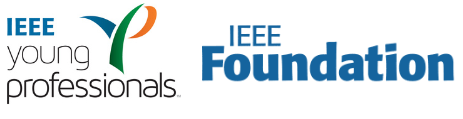